Cell 1: Import thư viện & Cố định Seed

In [ ]:
import time
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets

# Cố định seed tái lập kết quả
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch version:", torch.__version__)
print("Using device:", device)

PyTorch version: 2.14.1+cu130
Using device: cuda
PyTorch version: 2.14.1+cu130
Using device: cuda


Cell 2: Tải dữ liệu MNIST & Tạo Dataset chuỗi

In [ ]:
# Tải bộ dữ liệu MNIST gốc
train_mnist = datasets.MNIST(root='./data', train=True, download=True)
test_mnist = datasets.MNIST(root='./data', train=False, download=True)

X_train_raw = train_mnist.data.numpy().astype('float32') / 255.0
y_train_temp = train_mnist.targets.numpy()

X_test_raw = test_mnist.data.numpy().astype('float32') / 255.0
y_test_temp = test_mnist.targets.numpy()

np.random.seed(2018)
maxToAdd = 8
size = 28

def build_seq_tensors(images, labels):
    n_samples = images.shape[0]
    # Chỉ tốn ~1.4 GB RAM cho 60.000 mẫu float32 (rất nhẹ với 12.7 GB RAM của Colab)
    x_seq = np.zeros((n_samples, maxToAdd, 1, size, size), dtype=np.float32)
    y_seq = np.zeros(n_samples, dtype=np.float32)
    for i in range(n_samples):
        numToAdd = int(np.ceil(np.random.rand() * maxToAdd))
        indices = np.random.choice(n_samples, size=numToAdd)
        x_seq[i, 0:numToAdd, 0, :, :] = images[indices]
        y_seq[i] = np.sum(labels[indices])
    return torch.from_numpy(x_seq), torch.from_numpy(y_seq)

x_train_t, y_train_t = build_seq_tensors(X_train_raw, y_train_temp)
x_test_t, y_test_t = build_seq_tensors(X_test_raw, y_test_temp)

# Giải phóng mảng thô để tiết kiệm RAM
del X_train_raw, X_test_raw

from torch.utils.data import TensorDataset
train_dataset = TensorDataset(x_train_t, y_train_t)
test_dataset = TensorDataset(x_test_t, y_test_t)

batch_size = 128
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, pin_memory=True)

print("x_train:", x_train_t.shape, "| x_test:", x_test_t.shape)

x_train: torch.Size([60000, 8, 1, 28, 28]) | x_test: torch.Size([10000, 8, 1, 28, 28])


Cell 3: Xây dựng mô hình MNIST_CNN_LSTM & Kiểm tra số tham số

In [ ]:
class MNIST_CNN_LSTM(nn.Module):
    def __init__(self):
        super().__init__()
        # Khối CNN tương đương TimeDistributed(Conv2D + MaxPooling2D + Dropout)
        self.cnn = nn.Sequential(
            # Block 1: (1, 28, 28) -> (64, 14, 14)
            nn.Conv2d(1, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Dropout(0.2),

            # Block 2: (64, 14, 14) -> (128, 7, 7)
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Dropout(0.2),

            # Block 3: (128, 7, 7) -> (256, 3, 3)
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Dropout(0.2),

            nn.Flatten() # 256 * 3 * 3 = 2304
        )

        # Khối LSTM 2 tầng
        self.lstm1 = nn.LSTM(input_size=2304, hidden_size=128, batch_first=True)
        self.lstm2 = nn.LSTM(input_size=128, hidden_size=128, batch_first=True)
        self.lstm_dropout = nn.Dropout(0.22)
        self.fc = nn.Linear(128, 1)

    def forward(self, x):
        # x shape: (B, T, C, H, W) = (B, 8, 1, 28, 28)
        b, t, c, h, w = x.size()
        x = x.view(b * t, c, h, w)      # Gộp B*T thay cho TimeDistributed
        x = self.cnn(x)                 # (B*T, 2304)
        x = x.view(b, t, -1)            # (B, 8, 2304)

        x, _ = self.lstm1(x)            # (B, 8, 128)
        x, _ = self.lstm2(x)            # (B, 8, 128)
        x = x[:, -1, :]                 # Lấy bước thời gian cuối cùng (B, 128)
        x = self.lstm_dropout(x)
        out = self.fc(x)                # (B, 1)
        return out.squeeze(-1)

model = MNIST_CNN_LSTM().to(device)
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total params: {total_params:,}")
print(f"Trainable params: {trainable_params:,}") # Khớp đúng 1,748,097

Total params: 1,748,097
Trainable params: 1,748,097


Cell 4: Huấn luyện mô hình

In [ ]:
criterion = nn.L1Loss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)
epochs = 30

history = {'train_loss': [], 'val_loss': []}
start_time = time.time()

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    for inputs, targets in train_loader:
        inputs = inputs.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * inputs.size(0)

    train_mae = running_loss / len(train_dataset)

    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for inputs, targets in test_loader:
            inputs = inputs.to(device, non_blocking=True)
            targets = targets.to(device, non_blocking=True)
            outputs = model(inputs)
            val_loss += criterion(outputs, targets).item() * inputs.size(0)

    val_mae = val_loss / len(test_dataset)
    history['train_loss'].append(train_mae)
    history['val_loss'].append(val_mae)
    print(f"Epoch {epoch+1:02d}/{epochs} - loss: {train_mae:.4f} - val_loss: {val_mae:.4f}")

print(f"> training time is {(time.time() - start_time)/60:.4f} minutes")

Epoch 01/30 - loss: 8.9102 - val_loss: 4.5190
Epoch 02/30 - loss: 3.7166 - val_loss: 3.0127
Epoch 03/30 - loss: 2.8233 - val_loss: 1.8986
Epoch 04/30 - loss: 2.2389 - val_loss: 1.8997
Epoch 05/30 - loss: 1.8706 - val_loss: 1.2982
Epoch 06/30 - loss: 1.6801 - val_loss: 1.2417
Epoch 07/30 - loss: 1.5348 - val_loss: 1.2628
Epoch 08/30 - loss: 1.4369 - val_loss: 1.0434
Epoch 09/30 - loss: 1.3742 - val_loss: 0.9220
Epoch 10/30 - loss: 1.3199 - val_loss: 0.9278
Epoch 11/30 - loss: 1.2673 - val_loss: 1.1588
Epoch 12/30 - loss: 1.2287 - val_loss: 0.7610
Epoch 13/30 - loss: 1.1911 - val_loss: 0.7586
Epoch 14/30 - loss: 1.1584 - val_loss: 0.7761
Epoch 15/30 - loss: 1.1284 - val_loss: 0.8529
Epoch 16/30 - loss: 1.1103 - val_loss: 0.8659
Epoch 17/30 - loss: 1.0867 - val_loss: 0.9135
Epoch 18/30 - loss: 1.0620 - val_loss: 0.6418
Epoch 19/30 - loss: 1.0426 - val_loss: 0.6537
Epoch 20/30 - loss: 1.0300 - val_loss: 0.8372
Epoch 21/30 - loss: 1.0176 - val_loss: 0.6892
Epoch 22/30 - loss: 1.0041 - val_l

Cell 5: Đánh giá trên tập Test & Vẽ trực quan hóa

Mean absolute error of testing set: 0.548638


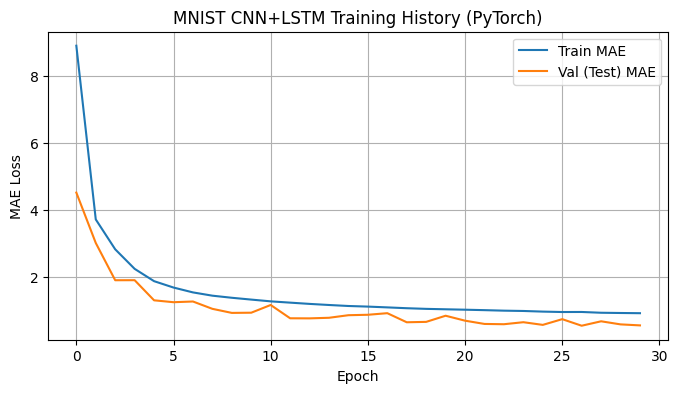

> actual summation = 7
> estimated summation = 6.620


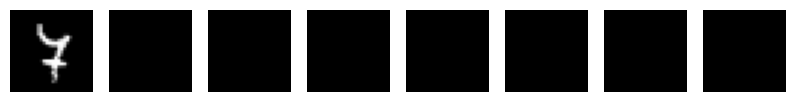

In [ ]:
model.eval()
test_loss = 0.0
with torch.no_grad():
    for inputs, targets in test_loader:
        inputs, targets = inputs.to(device), targets.to(device)
        outputs = model(inputs)
        test_loss += criterion(outputs, targets).item() * inputs.size(0)

final_mae = test_loss / len(test_dataset)
print(f"Mean absolute error of testing set: {final_mae:.6f}")

# Biểu đồ quá trình huấn luyện
plt.figure(figsize=(8, 4))
plt.plot(history['train_loss'], label='Train MAE')
plt.plot(history['val_loss'], label='Val (Test) MAE')
plt.xlabel('Epoch')
plt.ylabel('MAE Loss')
plt.title('MNIST CNN+LSTM Training History (PyTorch)')
plt.legend()
plt.grid(True)
plt.show()

# Dự đoán thử 1 chuỗi ngẫu nhiên trên tập test
random_test_index = np.random.choice(len(test_dataset), size=1)[0]
sample_seq, actual_sum = test_dataset[random_test_index]

with torch.no_grad():
    est_sum = model(sample_seq.unsqueeze(0).to(device)).item()

plt.figure(figsize=(10, 2.5))
for indx in range(maxToAdd):
    plt.subplot(1, maxToAdd, indx + 1)
    plt.axis('off')
    plt.imshow(sample_seq[indx, 0].numpy(), cmap='gray')

print(f"> actual summation = {int(actual_sum.item())}")
print(f"> estimated summation = {est_sum:.3f}")
plt.show()